In [1]:
import os
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms.community import greedy_modularity_communities
from networkx.exception import NetworkXError
from networkx.algorithms.community.quality import modularity

In [2]:
def parse_and_clean_gml(filepath):
  with open(filepath, 'r') as f:
      lines = f.readlines()

  nodes = set()
  edges = set()
  in_edge = False
  in_node = False
  source = target = None
  node_id = None

  for line in lines:
    line = line.strip()
    if line.startswith("node"):
      in_node = True
    elif line.startswith("edge"):
      in_edge = True
    elif line == "]":
      if in_node:
        if node_id is not None:
          nodes.add(node_id)
        in_node = False
        node_id = None
      if in_edge:
        if source is not None and target is not None:
          edge = tuple(sorted((source, target)))
          edges.add(edge)
        in_edge = False
        source = target = None
    elif in_node and line.startswith("id"):
      node_id = int(line.split()[1])
    elif in_edge:
      if line.startswith("source"):
        source = int(line.split()[1])
      elif line.startswith("target"):
        target = int(line.split()[1])

  G = nx.Graph()
  G.add_nodes_from(nodes)
  G.add_edges_from(edges)

  return G


In [3]:
def convert_node_to_community(communities):
  node_to_community = {}
  for comm_index, community in enumerate(communities):
    for node in community:
      node_to_community[node] = comm_index
  return node_to_community


In [4]:
def run(filename, label='id'):
  try:
    G = nx.read_gml(filename, label=label)
  except NetworkXError as e:
    print(f"Error reading GML file: {e}")
    G = parse_and_clean_gml(filename)
  communities = list(greedy_modularity_communities(G))

  print('Detected communities: ', len(communities))
  node_to_community = convert_node_to_community(communities)

  pos = nx.spring_layout(G, seed=12)
  colors = [node_to_community[node] for node in G.nodes()]

  plt.figure(figsize=(20, 20))
  nx.draw(G, pos, node_color=colors, with_labels=True, cmap=plt.cm.Set3)
  plt.title("Detected Communities for " + filename.split('/')[-1])
  plt.show()

  for comm_index, community in enumerate(communities):
    print(f'Community {comm_index} ({len(community)} nodes):')
    print(community)
    print()

  mod = modularity(G, communities)
  print('Modularity: ', mod)


In [5]:
dir_path = os.path.join(os.getcwd())


Detected communities:  4


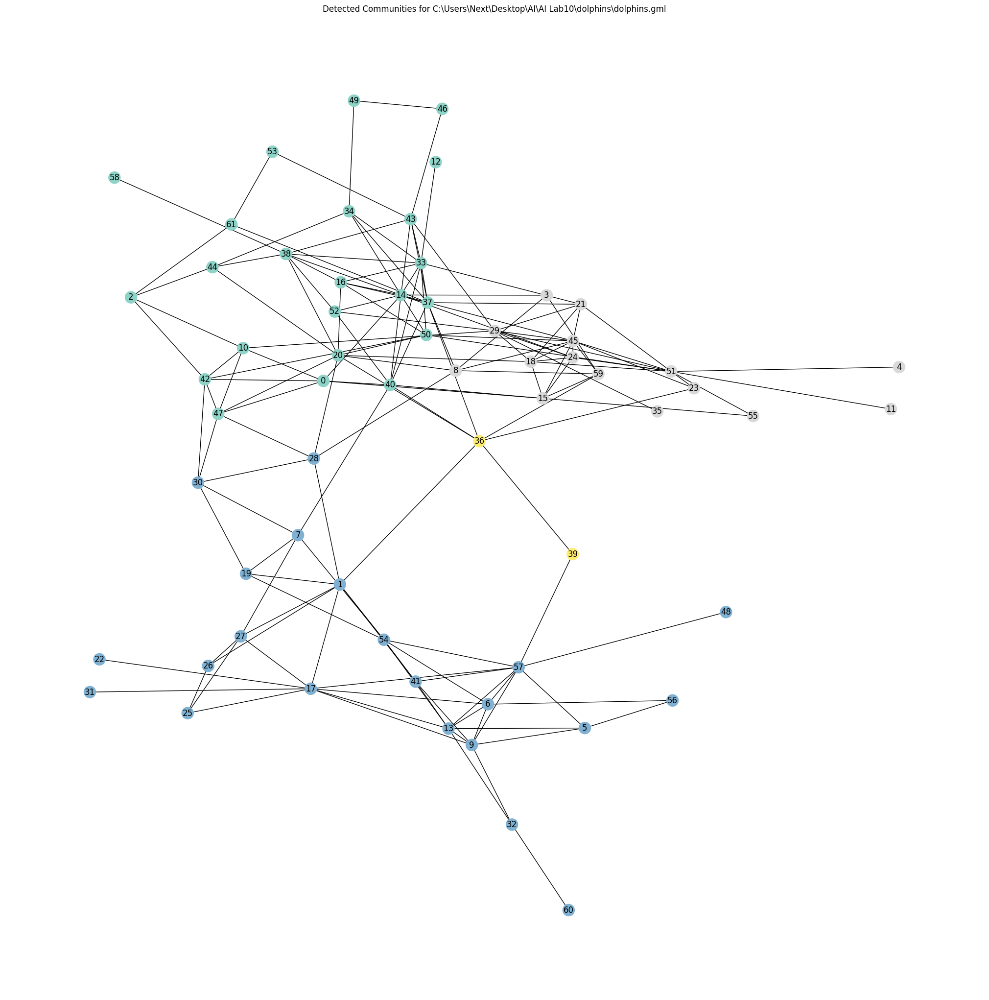

Community 0 (23 nodes):
frozenset({0, 2, 10, 12, 14, 16, 20, 33, 34, 37, 38, 40, 42, 43, 44, 46, 47, 49, 50, 52, 53, 58, 61})

Community 1 (22 nodes):
frozenset({1, 5, 6, 7, 9, 13, 17, 19, 22, 25, 26, 27, 28, 30, 31, 32, 41, 48, 54, 56, 57, 60})

Community 2 (15 nodes):
frozenset({35, 3, 4, 8, 11, 45, 15, 18, 51, 21, 55, 23, 24, 59, 29})

Community 3 (2 nodes):
frozenset({36, 39})

Modularity:  0.4954906847039278


In [8]:
filename = os.path.join(dir_path, 'dolphins', 'dolphins.gml')
run(filename)


Detected communities:  3


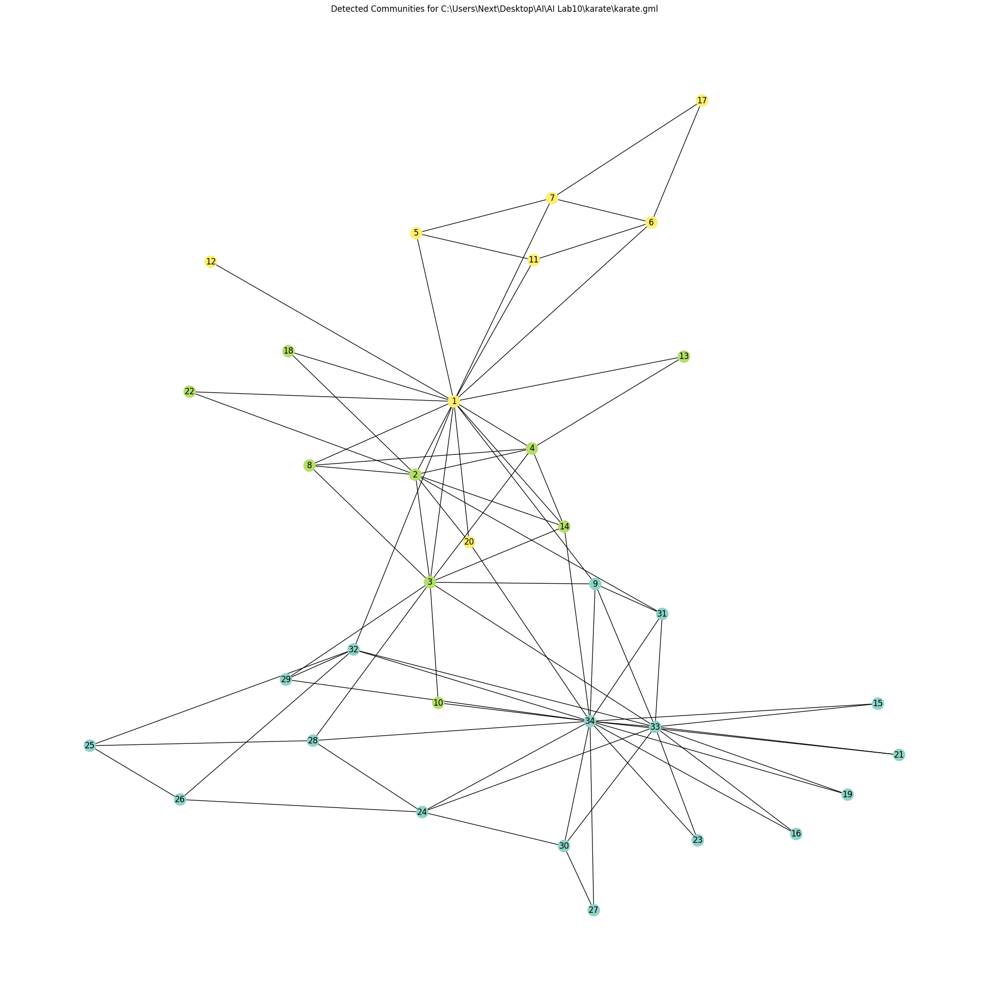

Community 0 (17 nodes):
frozenset({9, 15, 16, 19, 21, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34})

Community 1 (9 nodes):
frozenset({2, 3, 4, 8, 10, 13, 14, 18, 22})

Community 2 (8 nodes):
frozenset({1, 17, 20, 5, 6, 7, 11, 12})

Modularity:  0.3806706114398422


In [9]:
filename = os.path.join(dir_path, 'karate', 'karate.gml')
run(filename)


Error reading GML file: edge #51 (27--17) is duplicated
Detected communities:  6


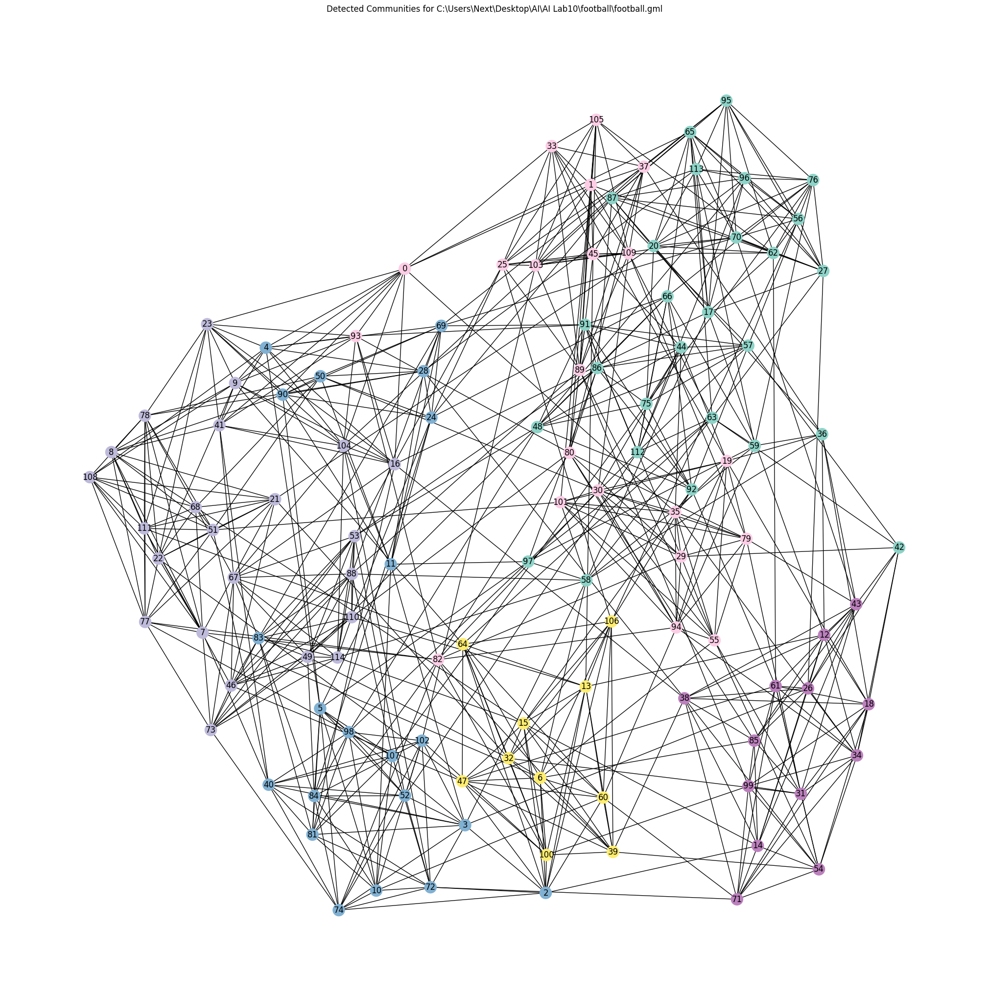

Community 0 (27 nodes):
frozenset({65, 66, 70, 75, 76, 17, 20, 86, 87, 27, 91, 92, 95, 96, 97, 36, 42, 44, 48, 112, 113, 56, 57, 58, 59, 62, 63})

Community 1 (23 nodes):
frozenset({67, 68, 7, 8, 73, 9, 77, 78, 16, 21, 22, 23, 88, 104, 41, 108, 110, 46, 111, 49, 114, 51, 53})

Community 2 (21 nodes):
frozenset({2, 3, 4, 5, 69, 72, 74, 10, 11, 81, 83, 84, 24, 90, 28, 98, 102, 40, 107, 50, 52})

Community 3 (21 nodes):
frozenset({0, 1, 79, 80, 82, 19, 89, 25, 93, 29, 30, 94, 33, 35, 101, 37, 103, 105, 109, 45, 55})

Community 4 (13 nodes):
frozenset({34, 99, 38, 71, 43, 12, 14, 18, 85, 54, 26, 61, 31})

Community 5 (10 nodes):
frozenset({64, 32, 100, 6, 39, 106, 13, 15, 47, 60})

Modularity:  0.5497406651426807


In [10]:
filename = os.path.join(dir_path, 'football', 'football.gml')
run(filename)


Detected communities:  4


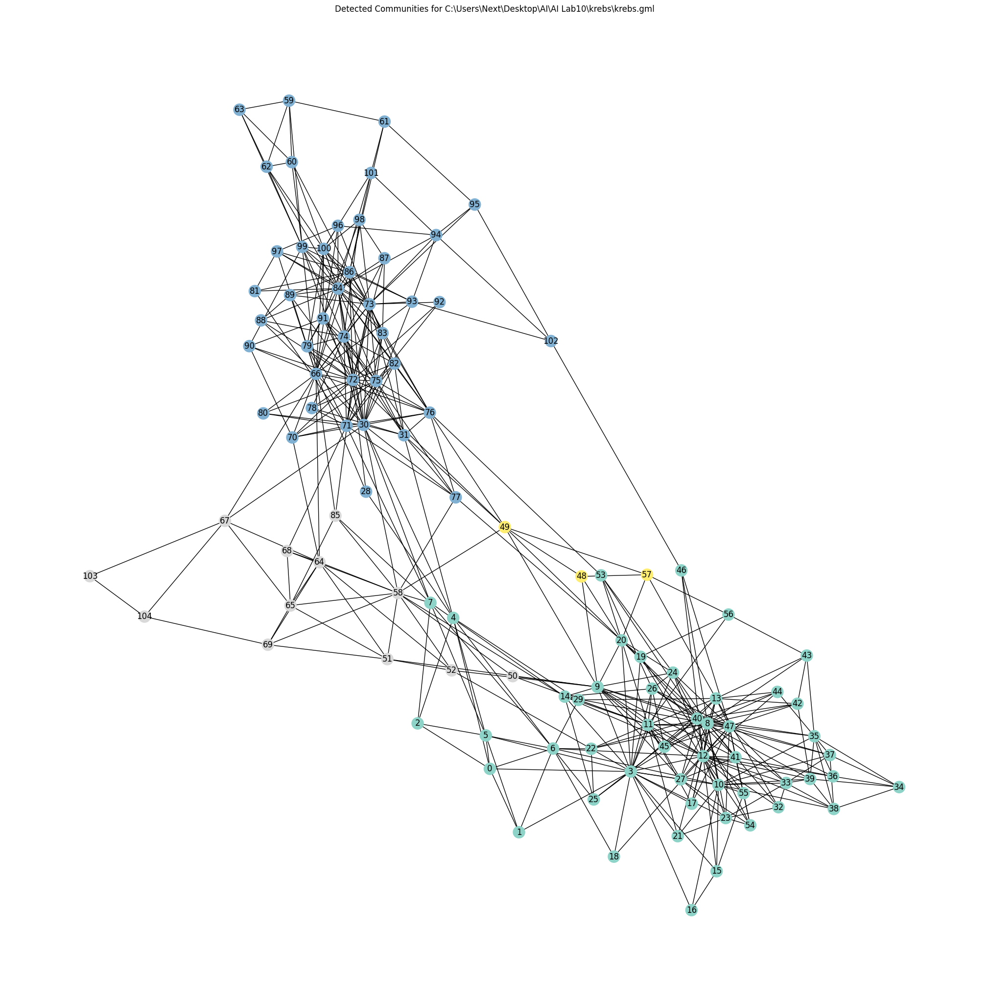

Community 0 (49 nodes):
frozenset({0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 29, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 53, 54, 55, 56})

Community 1 (41 nodes):
frozenset({28, 30, 31, 59, 60, 61, 62, 63, 66, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102})

Community 2 (12 nodes):
frozenset({64, 65, 67, 68, 69, 103, 104, 50, 51, 52, 85, 58})

Community 3 (3 nodes):
frozenset({48, 49, 57})

Modularity:  0.5019744859395006


In [11]:
filename = os.path.join(dir_path, 'krebs', 'krebs.gml')
run(filename)


In [15]:
from Chromosome import Chromosome


In [6]:
def my_modularity(communities, param):
  noNodes = param['noNodes']
  mat = param['mat']
  degrees = param['degrees']
  noEdges = param['noEdges']
  M = 2 * noEdges
  Q = 0.0
  for i in range(0, noNodes):
      for j in range(0, noNodes):
          if (communities[i] == communities[j]):
              Q += (mat[i][j] - degrees[i] * degrees[j] / M)
  return Q * 1 / M


In [7]:
def evaluate_community_fitness(graph, chromosome):
  comm_dict = {}
  for node_idx, comm_id in enumerate(chromosome.repres):
      comm_dict.setdefault(comm_id, []).append(node_idx)
  communities = list(comm_dict.values())
  return modularity(graph, communities)


In [8]:
import random

def run_ga(graph, pop_size=30, generations=10, mutation_rate=0.1, max_comms=5):
  num_nodes = graph.number_of_nodes()
  problParam = {'num_nodes': num_nodes, 'max_comms': max_comms}

  population = [Chromosome(problParam) for _ in range(pop_size)]
  for chrom in population:
    chrom.fitness = evaluate_community_fitness(graph, chrom)

  for gen in range(generations):
    elite = max(population, key=lambda c: c.fitness) ## elitism
    new_population = [elite]
    for _ in range(pop_size):
      p1, p2 = random.sample(population, 2)
      offspring = p1.crossover(p2)
      if random.random() < mutation_rate:
          offspring.mutation()
      offspring.fitness = evaluate_community_fitness(graph, offspring)
      new_population.append(offspring)

    population = new_population
    best = max(population, key=lambda c: c.fitness)
    if gen % 100 == 0:
      print(f"Gen {gen}: Best fitness = {best.fitness:.4f}")

  return max(population, key=lambda c: c.fitness)


In [9]:
def draw_communities(graph, chromosome):
  node_community_map = {node: comm for node, comm in enumerate(chromosome.repres)}
  pos = nx.spring_layout(graph, seed=12)
  colors = [node_community_map[node] for node in graph.nodes()]

  plt.figure(figsize=(15, 15))
  nx.draw_networkx(graph, pos, node_color=colors, with_labels=True, cmap=plt.cm.Set3)
  plt.title("Comunități detectate de algoritmul genetic")
  plt.show()


In [10]:
from collections import defaultdict
def run_my_ga(filename, label='id', pop_size=40, generations=200, mutation_rate=0.1, max_comms=3):
  max_comms = max_comms - 1
  try:
    G = nx.read_gml(filename, label=label)
    G = nx.convert_node_labels_to_integers(G, ordering='default')
  except NetworkXError as e:
    print(f"Error reading GML file: {e}")
    G = parse_and_clean_gml(filename)

  best_chromo = run_ga(G, pop_size=pop_size, generations=generations, mutation_rate=mutation_rate, max_comms=max_comms)

  comm_map = defaultdict(list)
  for idx, comm_id in enumerate(best_chromo.repres):
    comm_map[comm_id].append(idx)

  print(f"\n Număr comunități detectate: {len(comm_map)}")
  for cid, members in comm_map.items():
    print(f"Comunitatea {cid}: {members}")

  draw_communities(G, best_chromo)



Gen 0: Best fitness = 0.0566
Gen 100: Best fitness = 0.2213
Gen 200: Best fitness = 0.2593
Gen 300: Best fitness = 0.3027
Gen 400: Best fitness = 0.3230
Gen 500: Best fitness = 0.3301
Gen 600: Best fitness = 0.3409
Gen 700: Best fitness = 0.3476
Gen 800: Best fitness = 0.3542
Gen 900: Best fitness = 0.3865
Gen 1000: Best fitness = 0.3982
Gen 1100: Best fitness = 0.4016
Gen 1200: Best fitness = 0.4022
Gen 1300: Best fitness = 0.4049
Gen 1400: Best fitness = 0.4049
Gen 1500: Best fitness = 0.4096
Gen 1600: Best fitness = 0.4096
Gen 1700: Best fitness = 0.4096
Gen 1800: Best fitness = 0.4096
Gen 1900: Best fitness = 0.4096
Gen 2000: Best fitness = 0.4096
Gen 2100: Best fitness = 0.4096
Gen 2200: Best fitness = 0.4096
Gen 2300: Best fitness = 0.4096
Gen 2400: Best fitness = 0.4096
Gen 2500: Best fitness = 0.4096
Gen 2600: Best fitness = 0.4096
Gen 2700: Best fitness = 0.4096
Gen 2800: Best fitness = 0.4096
Gen 2900: Best fitness = 0.4106

 Număr comunități detectate: 3
Comunitatea 2: [0, 2

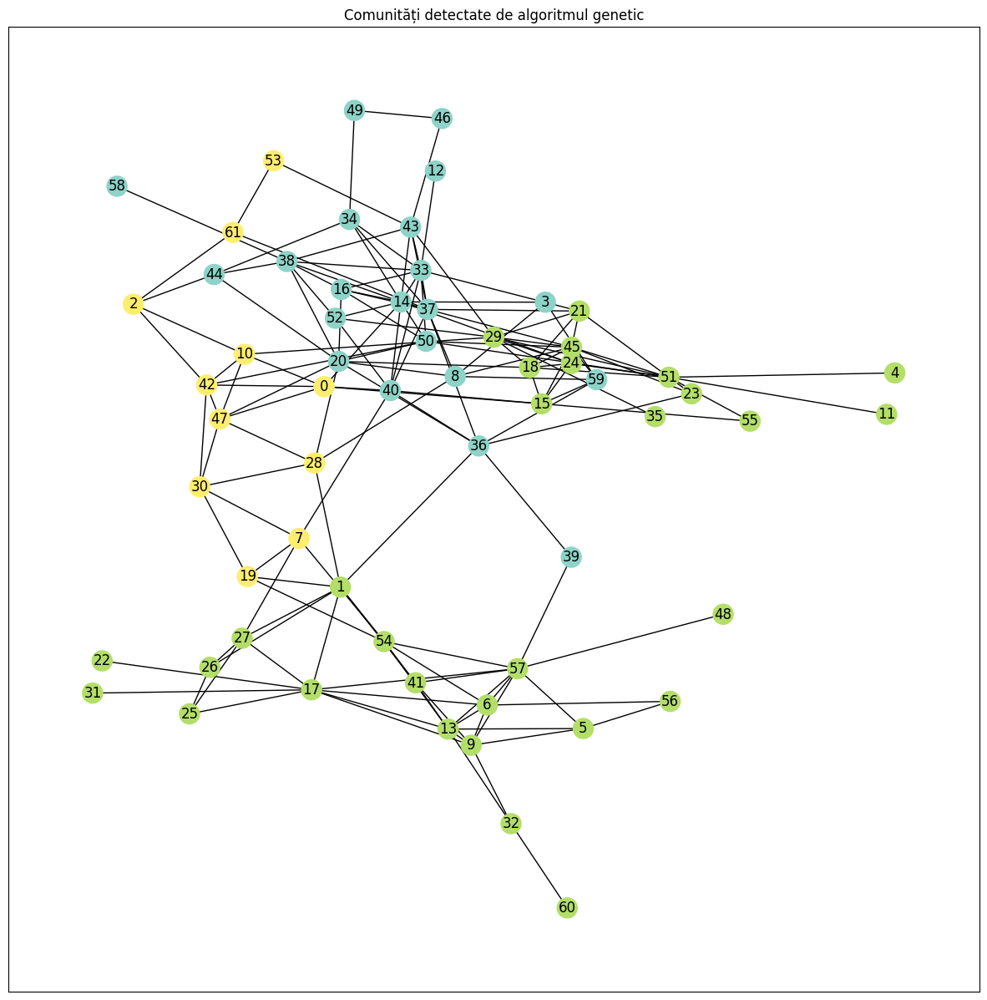

In [18]:
filename = os.path.join(dir_path, 'dolphins', 'dolphins.gml')
run_my_ga(filename, pop_size=50, generations=3000, mutation_rate=0.1, max_comms=3)


Error reading GML file: edge #51 (27--17) is duplicated
Gen 0: Best fitness = 0.0390
Gen 100: Best fitness = 0.0923
Gen 200: Best fitness = 0.1155
Gen 300: Best fitness = 0.1373
Gen 400: Best fitness = 0.1578
Gen 500: Best fitness = 0.1652
Gen 600: Best fitness = 0.1877
Gen 700: Best fitness = 0.2172
Gen 800: Best fitness = 0.2354
Gen 900: Best fitness = 0.2610
Gen 1000: Best fitness = 0.2801
Gen 1100: Best fitness = 0.3024
Gen 1200: Best fitness = 0.3128
Gen 1300: Best fitness = 0.3421
Gen 1400: Best fitness = 0.3781
Gen 1500: Best fitness = 0.4056
Gen 1600: Best fitness = 0.4158
Gen 1700: Best fitness = 0.4442
Gen 1800: Best fitness = 0.4548
Gen 1900: Best fitness = 0.4691
Gen 2000: Best fitness = 0.4731
Gen 2100: Best fitness = 0.4742
Gen 2200: Best fitness = 0.4849
Gen 2300: Best fitness = 0.4849
Gen 2400: Best fitness = 0.4858
Gen 2500: Best fitness = 0.4966
Gen 2600: Best fitness = 0.5064
Gen 2700: Best fitness = 0.5081
Gen 2800: Best fitness = 0.5081
Gen 2900: Best fitness = 0.5

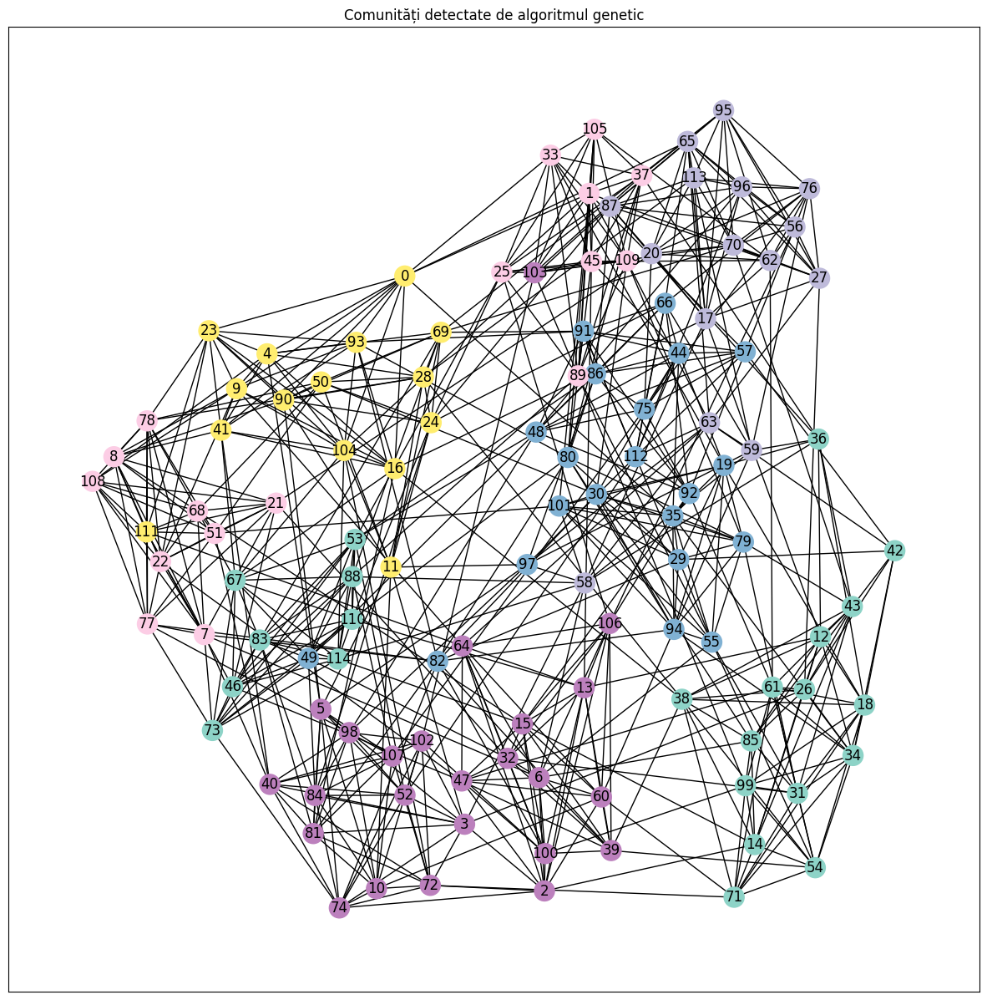

In [19]:
filename = os.path.join(dir_path, 'football', 'football.gml')
run_my_ga(filename, pop_size=50, generations=3000, mutation_rate=0.1, max_comms=6)


Gen 0: Best fitness = 0.1469
Gen 100: Best fitness = 0.3091
Gen 200: Best fitness = 0.3310
Gen 300: Best fitness = 0.3715
Gen 400: Best fitness = 0.3718
Gen 500: Best fitness = 0.3718
Gen 600: Best fitness = 0.3718
Gen 700: Best fitness = 0.3755
Gen 800: Best fitness = 0.3755
Gen 900: Best fitness = 0.3755
Gen 1000: Best fitness = 0.3755
Gen 1100: Best fitness = 0.3755
Gen 1200: Best fitness = 0.3755
Gen 1300: Best fitness = 0.3755
Gen 1400: Best fitness = 0.3755
Gen 1500: Best fitness = 0.3755
Gen 1600: Best fitness = 0.3755
Gen 1700: Best fitness = 0.3755
Gen 1800: Best fitness = 0.3755
Gen 1900: Best fitness = 0.3755

 Număr comunități detectate: 3
Comunitatea 0: [0, 1, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Comunitatea 1: [2, 9, 28]
Comunitatea 2: [8, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 29, 30, 31, 32, 33]


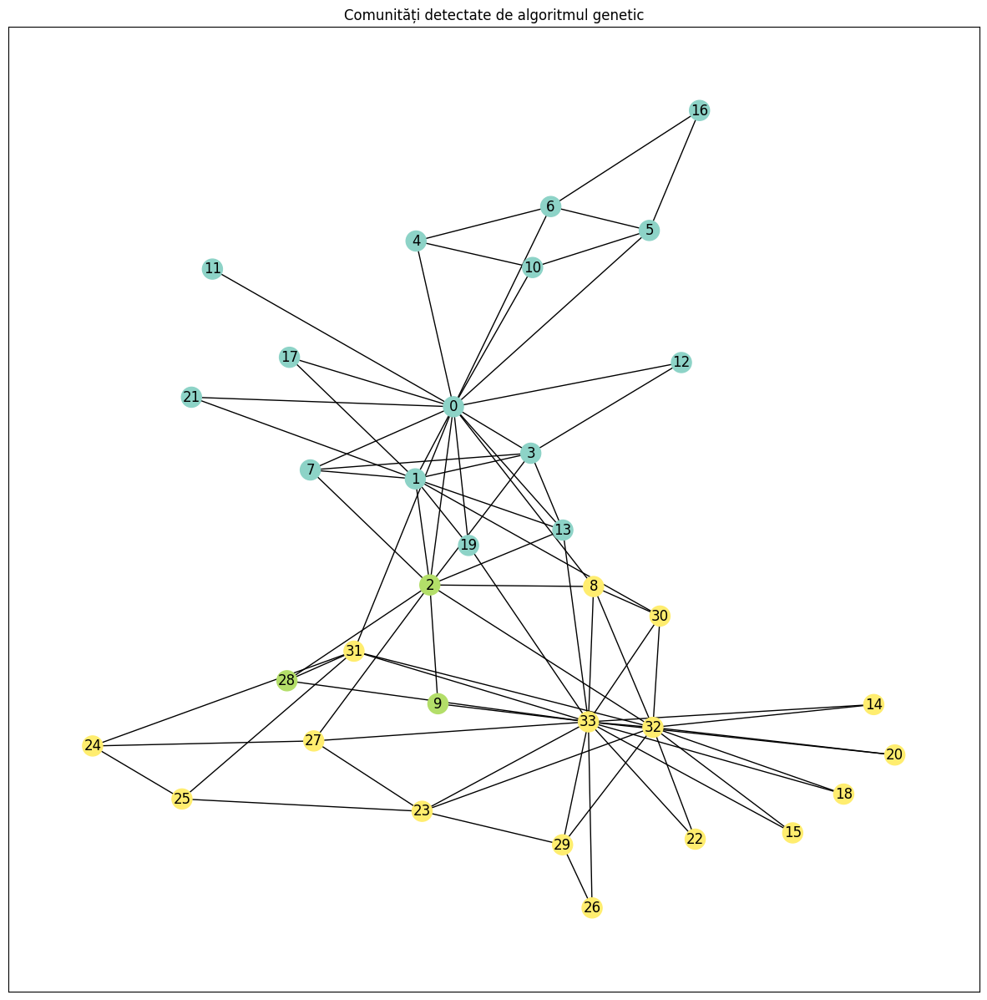

In [20]:
filename = os.path.join(dir_path, 'karate', 'karate.gml')
run_my_ga(filename, pop_size=50, generations=2000, mutation_rate=0.15, max_comms=3)


Gen 0: Best fitness = 0.0340
Gen 100: Best fitness = 0.1364
Gen 200: Best fitness = 0.2075
Gen 300: Best fitness = 0.2552
Gen 400: Best fitness = 0.2966
Gen 500: Best fitness = 0.3447
Gen 600: Best fitness = 0.3502
Gen 700: Best fitness = 0.3955
Gen 800: Best fitness = 0.3967
Gen 900: Best fitness = 0.4087
Gen 1000: Best fitness = 0.4341
Gen 1100: Best fitness = 0.4499
Gen 1200: Best fitness = 0.4607
Gen 1300: Best fitness = 0.4616
Gen 1400: Best fitness = 0.4697
Gen 1500: Best fitness = 0.4764
Gen 1600: Best fitness = 0.4789
Gen 1700: Best fitness = 0.4932
Gen 1800: Best fitness = 0.4975
Gen 1900: Best fitness = 0.5016
Gen 2000: Best fitness = 0.5016
Gen 2100: Best fitness = 0.5175
Gen 2200: Best fitness = 0.5175
Gen 2300: Best fitness = 0.5175
Gen 2400: Best fitness = 0.5175
Gen 2500: Best fitness = 0.5175
Gen 2600: Best fitness = 0.5221
Gen 2700: Best fitness = 0.5221
Gen 2800: Best fitness = 0.5221
Gen 2900: Best fitness = 0.5221

 Număr comunități detectate: 3
Comunitatea 1: [0, 1

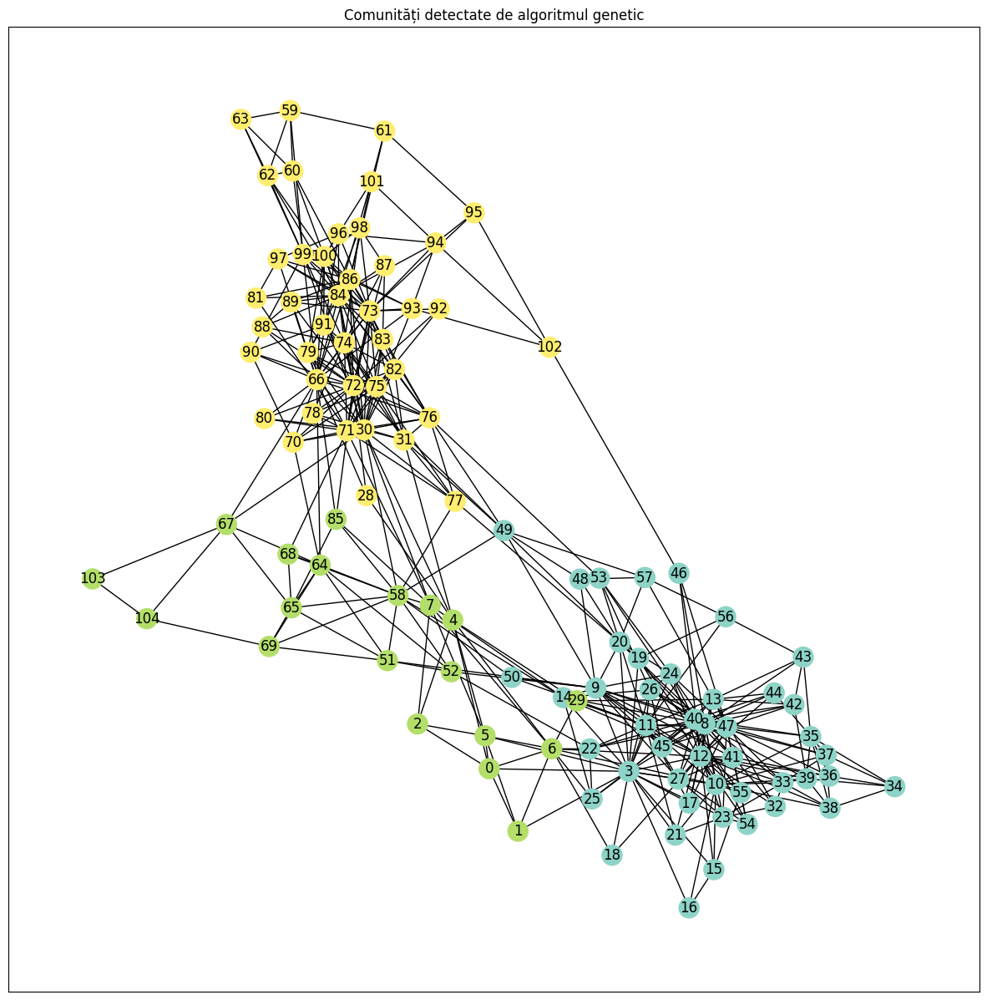

In [21]:
filename = os.path.join(dir_path, 'krebs', 'krebs.gml')
run_my_ga(filename, pop_size=50, generations=3000, mutation_rate=0.1, max_comms=3)

Error reading GML file: input is not ASCII-encoded
Detected communities:  3


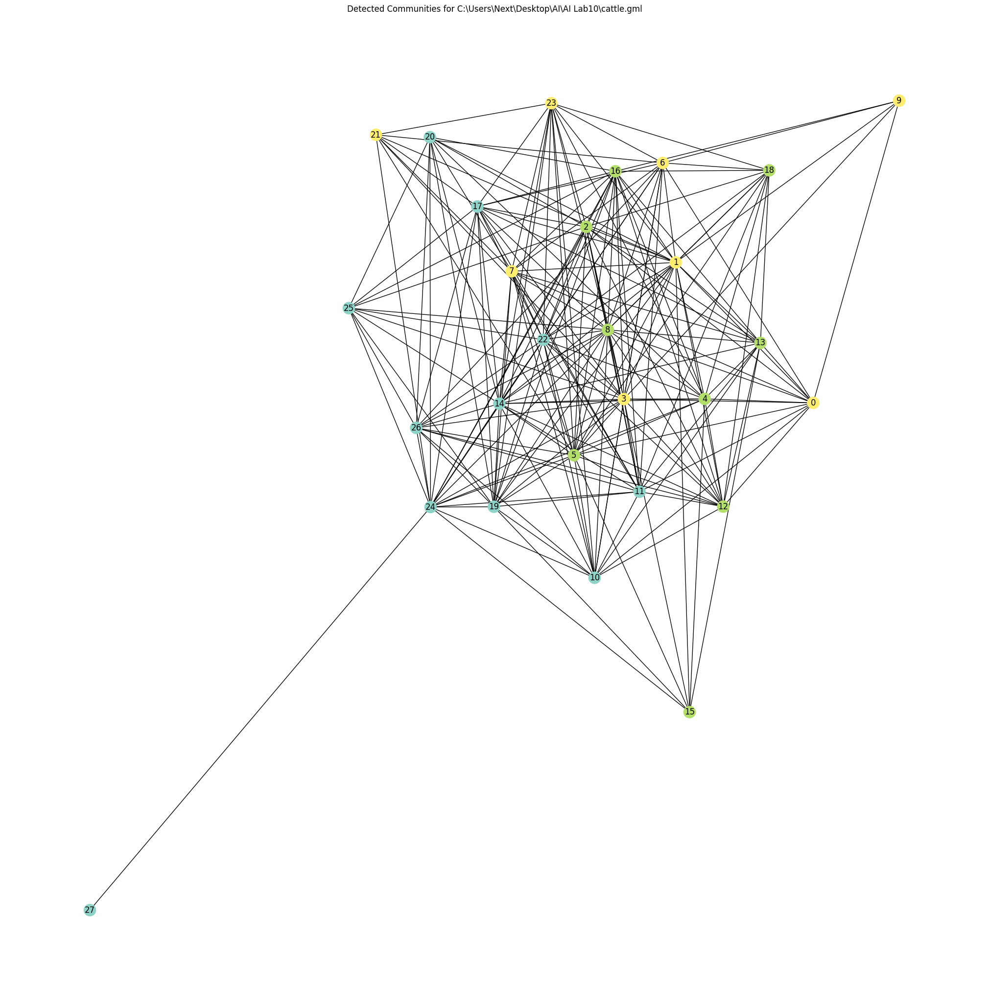

Community 0 (11 nodes):
frozenset({10, 11, 14, 17, 19, 20, 22, 24, 25, 26, 27})

Community 1 (9 nodes):
frozenset({2, 4, 5, 8, 12, 13, 15, 16, 18})

Community 2 (8 nodes):
frozenset({0, 1, 3, 23, 21, 6, 7, 9})

Modularity:  0.09419393218322422


In [23]:
filename = os.path.join(dir_path, 'cattle.gml')
run(filename)


Error reading GML file: input is not ASCII-encoded
Gen 0: Best fitness = 0.0113
Gen 100: Best fitness = 0.0771
Gen 200: Best fitness = 0.0955
Gen 300: Best fitness = 0.0983
Gen 400: Best fitness = 0.0983
Gen 500: Best fitness = 0.1002
Gen 600: Best fitness = 0.1010
Gen 700: Best fitness = 0.1017
Gen 800: Best fitness = 0.1017
Gen 900: Best fitness = 0.1022
Gen 1000: Best fitness = 0.1022
Gen 1100: Best fitness = 0.1022
Gen 1200: Best fitness = 0.1022
Gen 1300: Best fitness = 0.1022
Gen 1400: Best fitness = 0.1022
Gen 1500: Best fitness = 0.1022
Gen 1600: Best fitness = 0.1022
Gen 1700: Best fitness = 0.1022
Gen 1800: Best fitness = 0.1022
Gen 1900: Best fitness = 0.1022
Gen 2000: Best fitness = 0.1022
Gen 2100: Best fitness = 0.1022
Gen 2200: Best fitness = 0.1022
Gen 2300: Best fitness = 0.1022
Gen 2400: Best fitness = 0.1022
Gen 2500: Best fitness = 0.1022
Gen 2600: Best fitness = 0.1022
Gen 2700: Best fitness = 0.1022
Gen 2800: Best fitness = 0.1022
Gen 2900: Best fitness = 0.1022



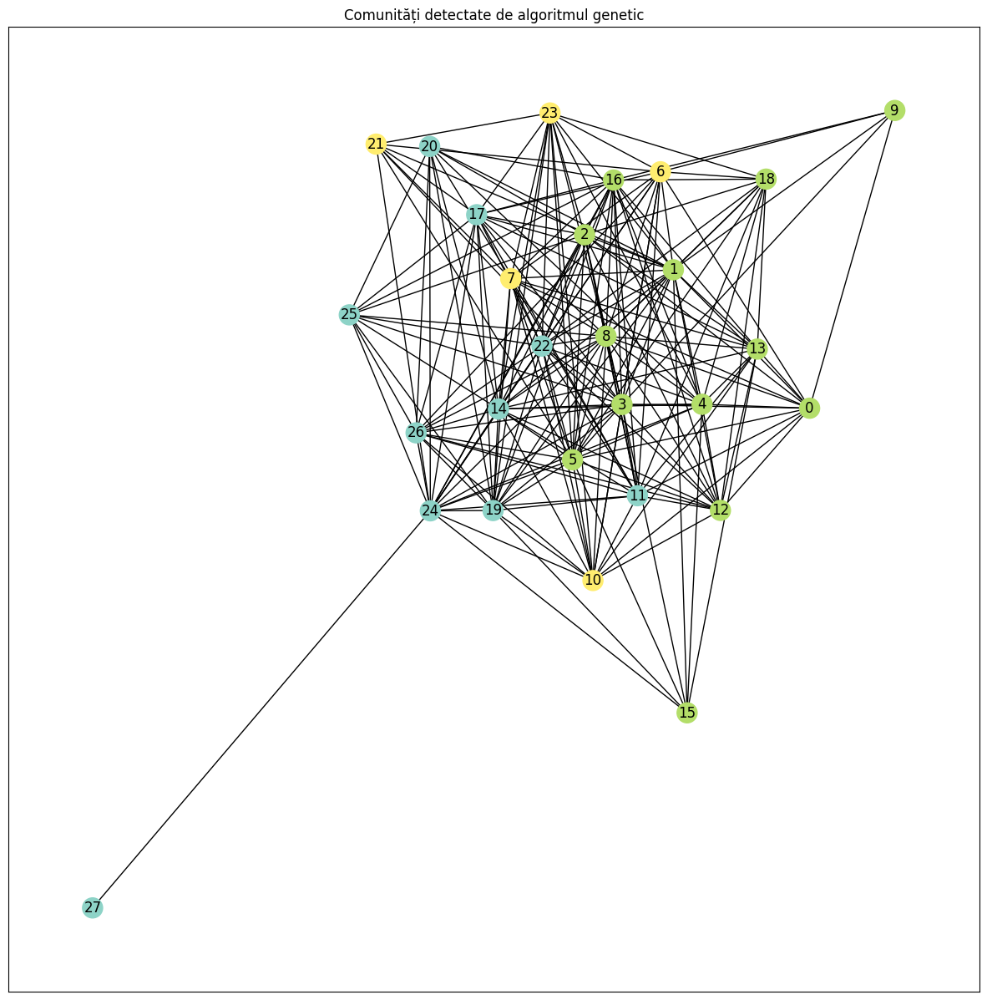

In [24]:
filename = os.path.join(dir_path, 'cattle.gml')
run_my_ga(filename, pop_size=50, generations=3000, mutation_rate=0.1, max_comms=3)


Error reading GML file: input is not ASCII-encoded
Detected communities:  4


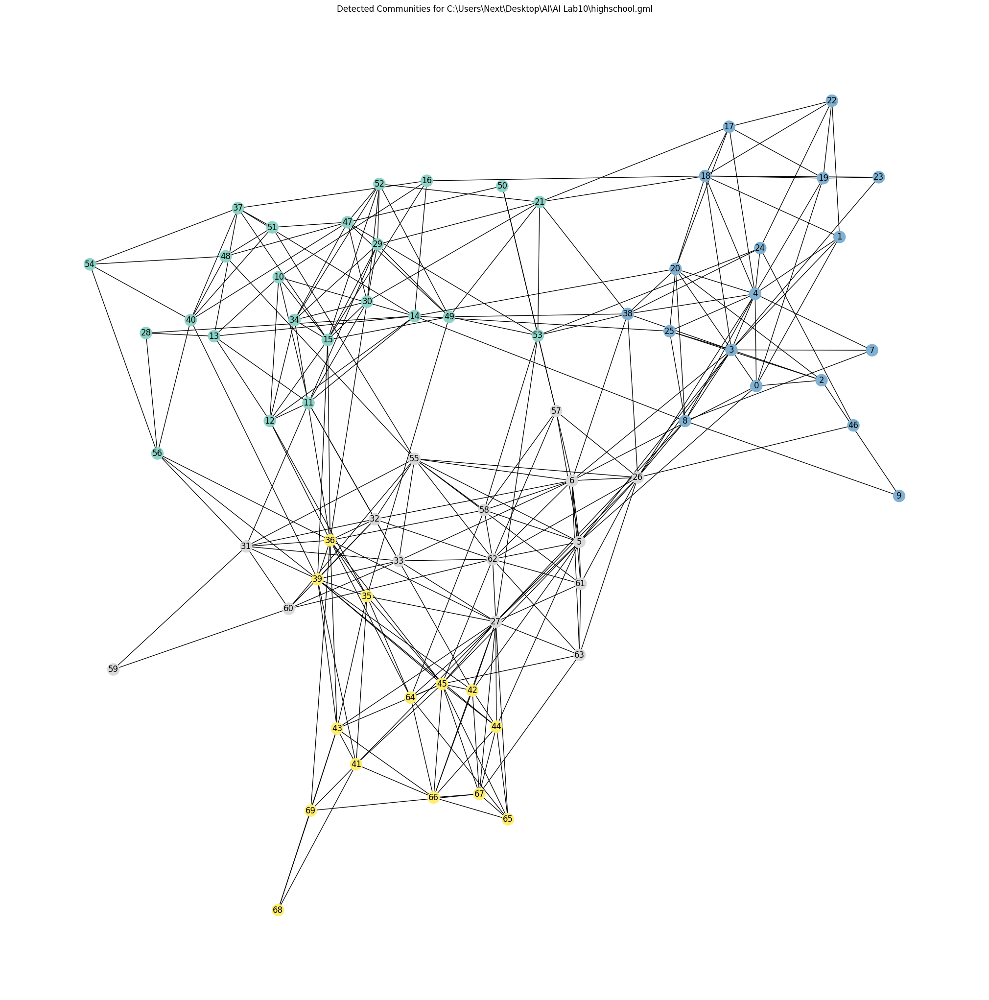

Community 0 (23 nodes):
frozenset({10, 11, 12, 13, 14, 15, 16, 21, 28, 29, 30, 34, 37, 40, 47, 48, 49, 50, 51, 52, 53, 54, 56})

Community 1 (18 nodes):
frozenset({0, 1, 2, 3, 4, 7, 8, 9, 17, 18, 19, 20, 22, 23, 24, 25, 38, 46})

Community 2 (15 nodes):
frozenset({32, 33, 58, 5, 6, 59, 31, 55, 57, 26, 27, 60, 61, 62, 63})

Community 3 (14 nodes):
frozenset({64, 65, 66, 67, 35, 36, 68, 69, 39, 41, 42, 43, 44, 45})

Modularity:  0.5055210719803932


In [25]:
filename = os.path.join(dir_path, 'highschool.gml')
run(filename)

Error reading GML file: input is not ASCII-encoded
Gen 0: Best fitness = 0.0515
Gen 100: Best fitness = 0.1609
Gen 200: Best fitness = 0.2405
Gen 300: Best fitness = 0.2709
Gen 400: Best fitness = 0.3070
Gen 500: Best fitness = 0.3362
Gen 600: Best fitness = 0.3555
Gen 700: Best fitness = 0.4059
Gen 800: Best fitness = 0.4304
Gen 900: Best fitness = 0.4524
Gen 1000: Best fitness = 0.4756
Gen 1100: Best fitness = 0.4756
Gen 1200: Best fitness = 0.4756
Gen 1300: Best fitness = 0.4761
Gen 1400: Best fitness = 0.4761

 Număr comunități detectate: 4
Comunitatea 0: [0, 1, 2, 3, 4, 7, 8, 9, 10, 11, 12, 13, 14, 16, 17, 18, 19, 20, 22, 23, 25, 28, 37]
Comunitatea 2: [5, 6, 26, 32, 33, 48, 51, 55, 57, 58, 59, 60, 61, 62, 63]
Comunitatea 3: [15, 21, 24, 29, 30, 34, 38, 46, 47, 49, 50, 52, 53]
Comunitatea 1: [27, 31, 35, 36, 39, 40, 41, 42, 43, 44, 45, 54, 56, 64, 65, 66, 67, 68, 69]


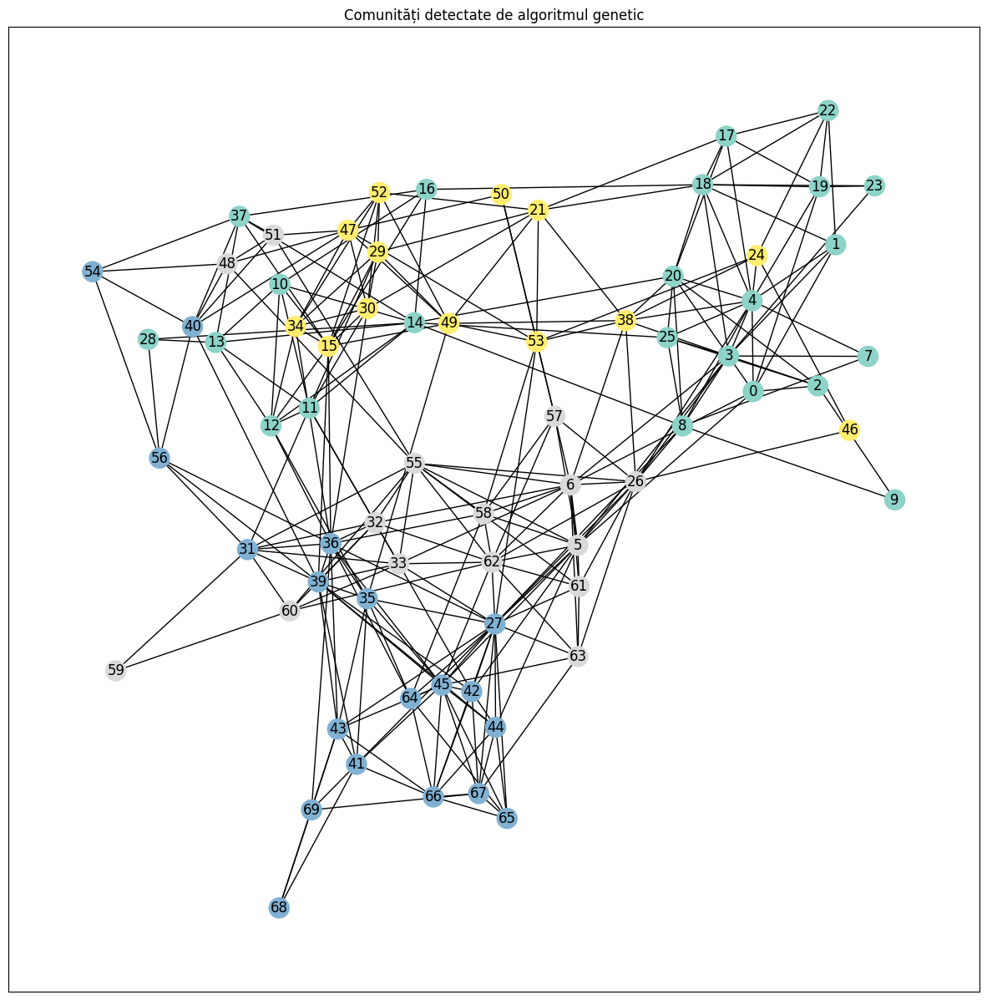

In [26]:
filename = os.path.join(dir_path, 'highschool.gml')
run_my_ga(filename, pop_size=50, generations=1500, mutation_rate=0.1, max_comms=4)


Detected communities:  275


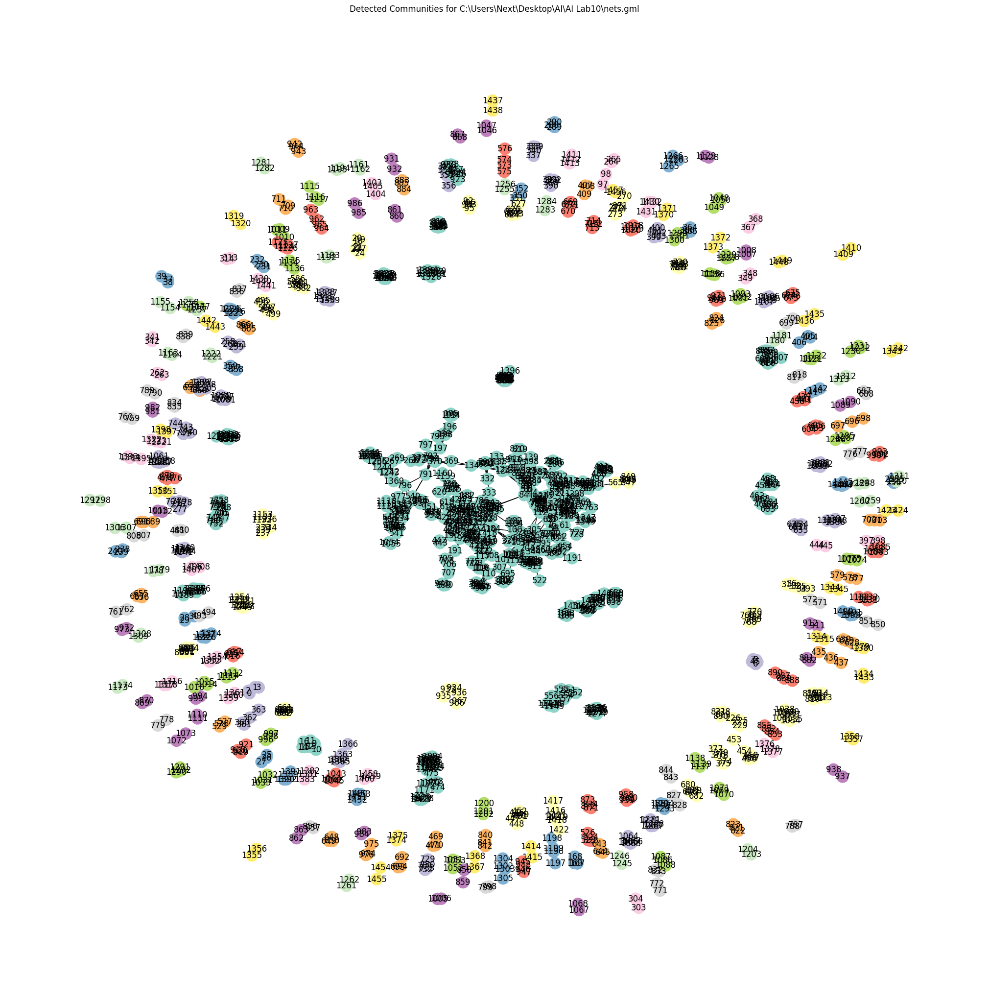

Community 0 (105 nodes):
frozenset({773, 774, 775, 780, 781, 782, 783, 784, 785, 786, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 558, 559, 302, 560, 561, 562, 563, 564, 305, 325, 326, 327, 328, 330, 332, 333, 334, 335, 336, 84, 85, 599, 600, 601, 602, 343, 344, 345, 346, 347, 886, 394, 395, 396, 1191, 170, 939, 940, 941, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 442, 443, 183, 184, 190, 185, 186, 187, 188, 189, 191, 706, 707, 192, 705, 708, 724, 725, 726, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254})

Community 1 (98 nodes):
frozenset({266, 267, 268, 269, 280, 281, 282, 283, 284, 285, 286, 287, 40, 41, 42, 43, 44, 45, 46, 49, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 86, 87, 88, 89, 90, 369, 370, 371, 372, 373, 1346, 1347, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 1348, 136, 137, 138, 651, 652, 653, 654, 139, 913, 914, 915, 9

In [11]:
filename = os.path.join(dir_path, 'nets.gml')
run(filename)


Gen 0: Best fitness = 0.0016
Gen 100: Best fitness = 0.0062
Gen 200: Best fitness = 0.0066
Gen 300: Best fitness = 0.0074
Gen 400: Best fitness = 0.0075
Gen 500: Best fitness = 0.0093
Gen 600: Best fitness = 0.0100
Gen 700: Best fitness = 0.0108
Gen 800: Best fitness = 0.0112
Gen 900: Best fitness = 0.0123
Gen 1000: Best fitness = 0.0130
Gen 1100: Best fitness = 0.0141
Gen 1200: Best fitness = 0.0156
Gen 1300: Best fitness = 0.0160
Gen 1400: Best fitness = 0.0164
Gen 1500: Best fitness = 0.0174
Gen 1600: Best fitness = 0.0179
Gen 1700: Best fitness = 0.0190
Gen 1800: Best fitness = 0.0197
Gen 1900: Best fitness = 0.0201
Gen 2000: Best fitness = 0.0208
Gen 2100: Best fitness = 0.0223
Gen 2200: Best fitness = 0.0227
Gen 2300: Best fitness = 0.0242
Gen 2400: Best fitness = 0.0242
Gen 2500: Best fitness = 0.0260
Gen 2600: Best fitness = 0.0267
Gen 2700: Best fitness = 0.0278
Gen 2800: Best fitness = 0.0286
Gen 2900: Best fitness = 0.0290

 Număr comunități detectate: 275
Comunitatea 64: [0

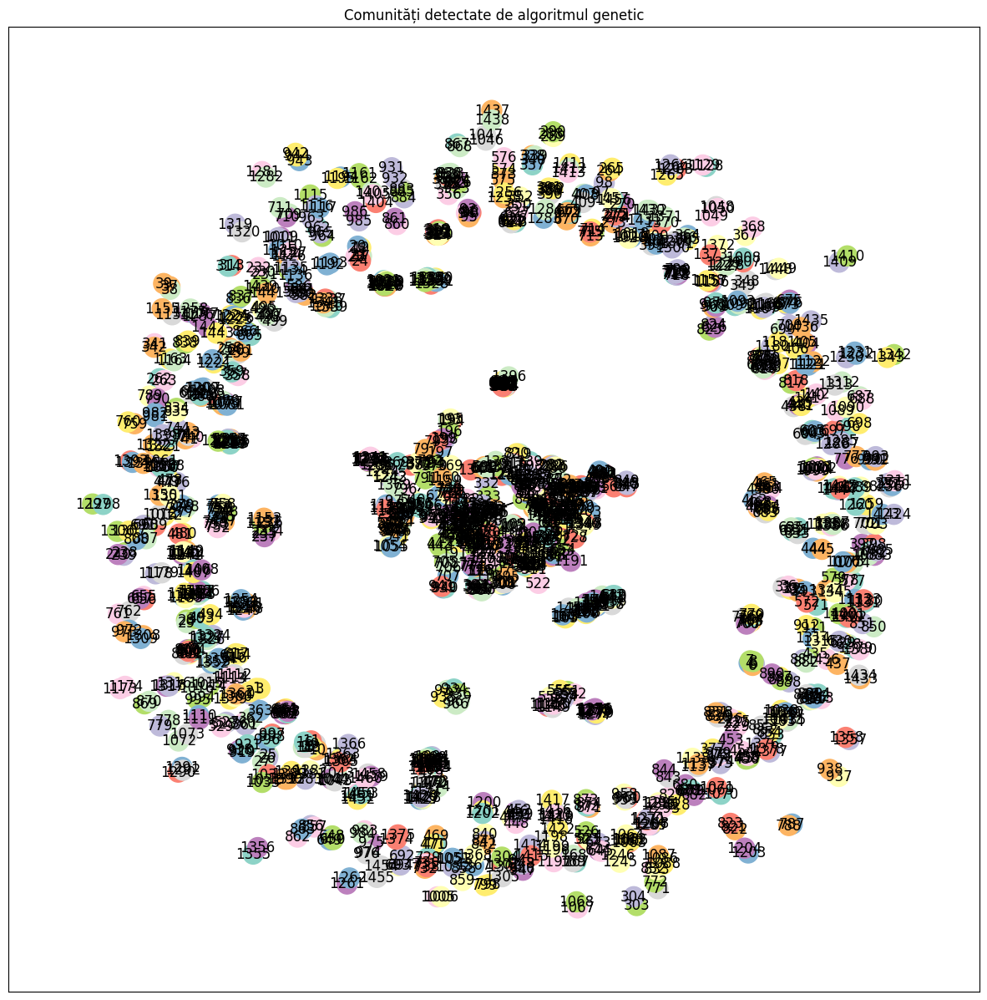

In [19]:
filename = os.path.join(dir_path, 'nets.gml')
run_my_ga(filename, pop_size=30, generations=3000, mutation_rate=0.1, max_comms=275)


Detected communities:  12


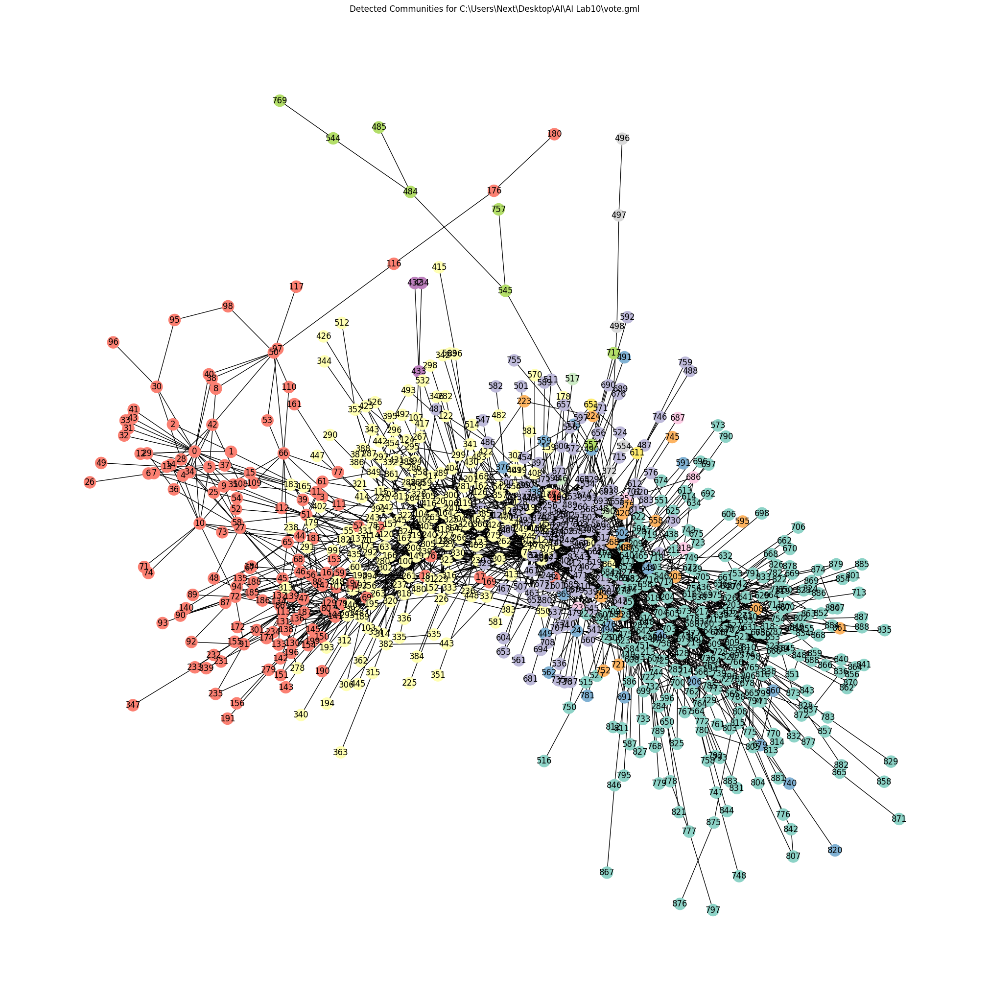

Community 0 (297 nodes):
frozenset({85, 171, 203, 204, 207, 208, 209, 212, 213, 214, 215, 216, 217, 219, 222, 269, 270, 271, 272, 273, 283, 284, 285, 375, 393, 428, 436, 438, 439, 440, 444, 465, 468, 470, 472, 475, 477, 478, 503, 504, 506, 509, 515, 516, 518, 519, 520, 521, 522, 523, 525, 527, 528, 538, 540, 546, 551, 552, 553, 564, 565, 566, 573, 578, 584, 586, 587, 588, 594, 596, 605, 606, 607, 608, 609, 610, 613, 614, 616, 622, 623, 624, 625, 626, 627, 628, 629, 630, 631, 632, 633, 634, 635, 636, 637, 638, 639, 640, 641, 642, 643, 648, 649, 650, 658, 659, 660, 661, 662, 663, 664, 665, 666, 667, 668, 669, 670, 672, 673, 674, 675, 677, 678, 682, 684, 688, 692, 695, 696, 697, 698, 699, 700, 702, 703, 704, 705, 706, 709, 711, 712, 713, 714, 716, 718, 719, 720, 722, 723, 724, 725, 726, 727, 728, 729, 731, 732, 733, 738, 739, 741, 742, 743, 744, 747, 748, 749, 750, 751, 753, 754, 756, 758, 760, 761, 762, 763, 764, 765, 766, 767, 768, 770, 771, 772, 773, 774, 775, 776, 777, 778, 779, 780, 

In [18]:
filename = os.path.join(dir_path, 'vote.gml')
run(filename)


Gen 0: Best fitness = 0.0084
Gen 100: Best fitness = 0.0228
Gen 200: Best fitness = 0.0263
Gen 300: Best fitness = 0.0310
Gen 400: Best fitness = 0.0351
Gen 500: Best fitness = 0.0387
Gen 600: Best fitness = 0.0428
Gen 700: Best fitness = 0.0473
Gen 800: Best fitness = 0.0513
Gen 900: Best fitness = 0.0539
Gen 1000: Best fitness = 0.0593
Gen 1100: Best fitness = 0.0625
Gen 1200: Best fitness = 0.0655
Gen 1300: Best fitness = 0.0686
Gen 1400: Best fitness = 0.0727
Gen 1500: Best fitness = 0.0757
Gen 1600: Best fitness = 0.0791
Gen 1700: Best fitness = 0.0851
Gen 1800: Best fitness = 0.0872
Gen 1900: Best fitness = 0.0912
Gen 2000: Best fitness = 0.0939
Gen 2100: Best fitness = 0.0966
Gen 2200: Best fitness = 0.0998
Gen 2300: Best fitness = 0.1015
Gen 2400: Best fitness = 0.1045
Gen 2500: Best fitness = 0.1084
Gen 2600: Best fitness = 0.1126
Gen 2700: Best fitness = 0.1155
Gen 2800: Best fitness = 0.1192
Gen 2900: Best fitness = 0.1206

 Număr comunități detectate: 12
Comunitatea 11: [0,

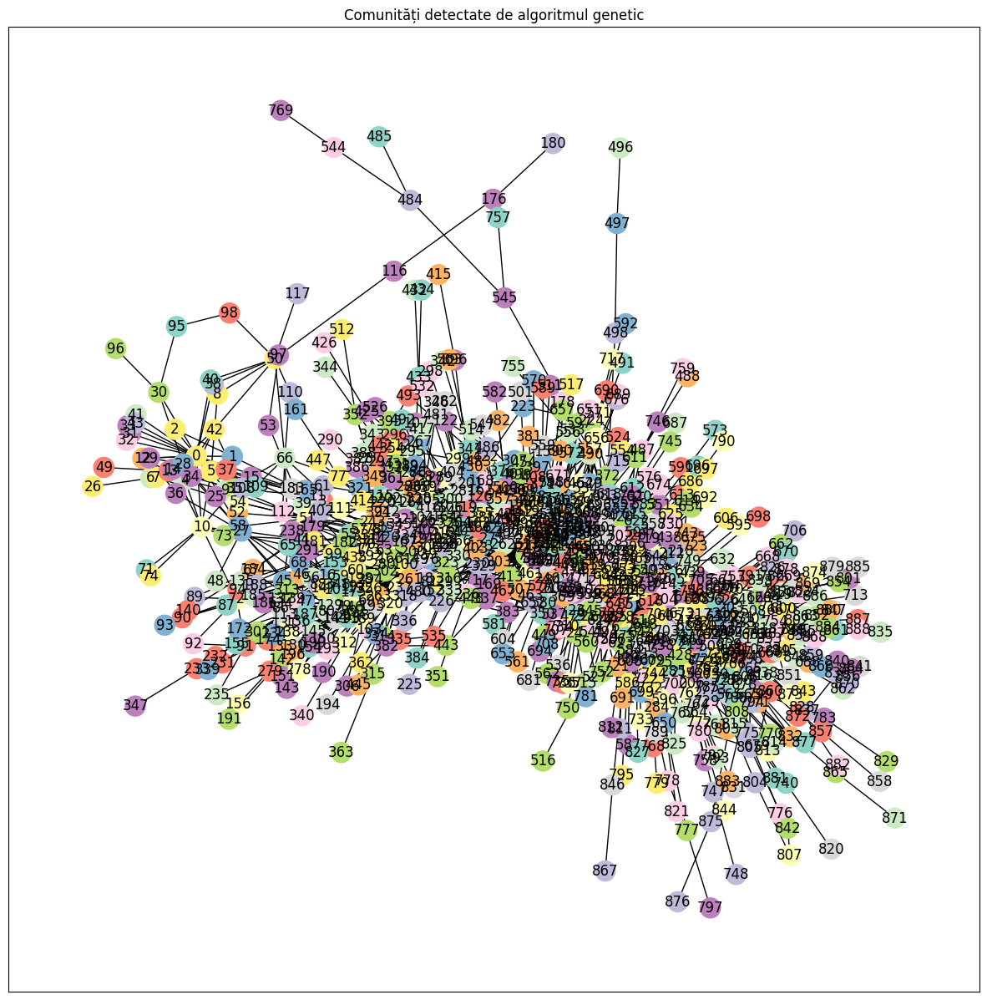

In [17]:
filename = os.path.join(dir_path, 'vote.gml')
run_my_ga(filename, pop_size=30, generations=3000, mutation_rate=0.1, max_comms=12)


Detected communities:  3


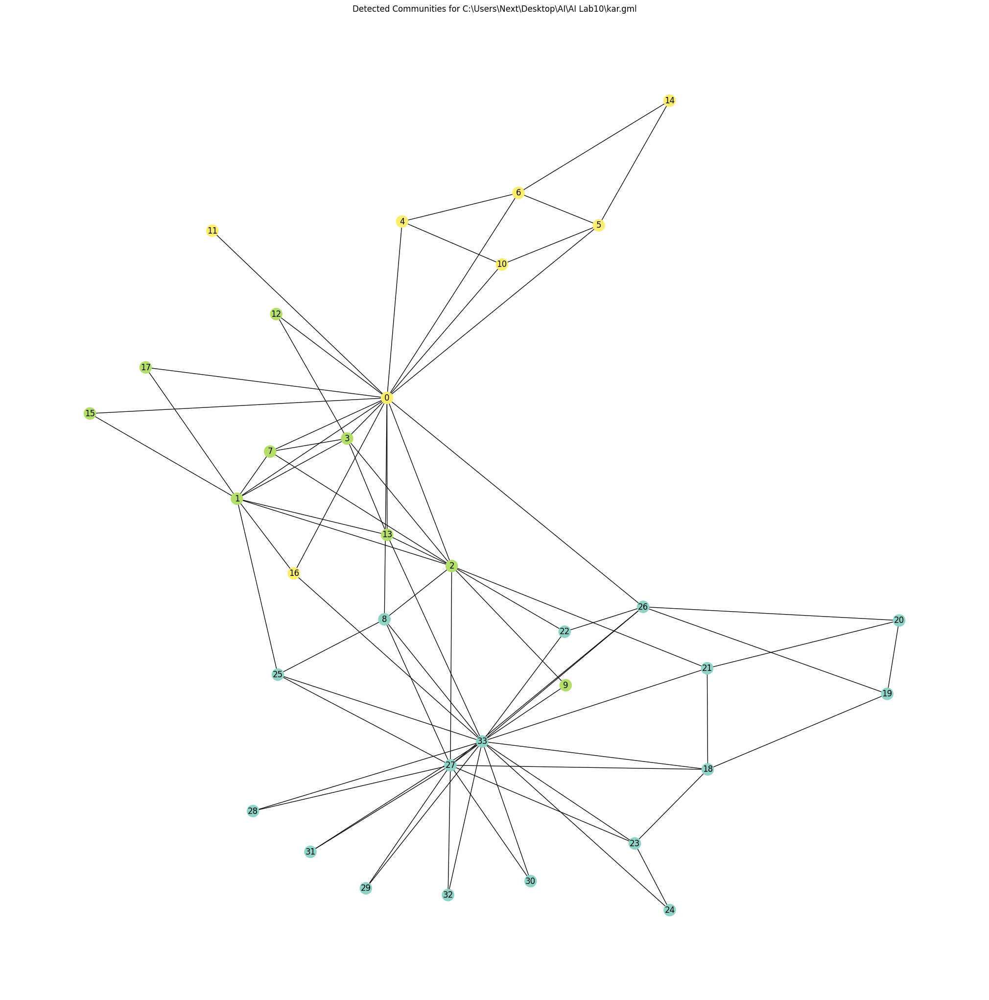

Community 0 (17 nodes):
frozenset({8, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33})

Community 1 (9 nodes):
frozenset({1, 2, 3, 7, 9, 12, 13, 15, 17})

Community 2 (8 nodes):
frozenset({0, 16, 4, 5, 6, 10, 11, 14})

Modularity:  0.3806706114398422


In [13]:
filename = os.path.join(dir_path, 'kar.gml')
run(filename)


Gen 0: Best fitness = 0.1095
Gen 100: Best fitness = 0.3130
Gen 200: Best fitness = 0.3416
Gen 300: Best fitness = 0.3811
Gen 400: Best fitness = 0.3814
Gen 500: Best fitness = 0.3814
Gen 600: Best fitness = 0.3814
Gen 700: Best fitness = 0.3814
Gen 800: Best fitness = 0.3814
Gen 900: Best fitness = 0.3814

 Număr comunități detectate: 3
Comunitatea 2: [0, 4, 5, 6, 10, 11, 12, 14, 15, 17]
Comunitatea 0: [1, 2, 3, 7, 9, 13, 16]
Comunitatea 1: [8, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]


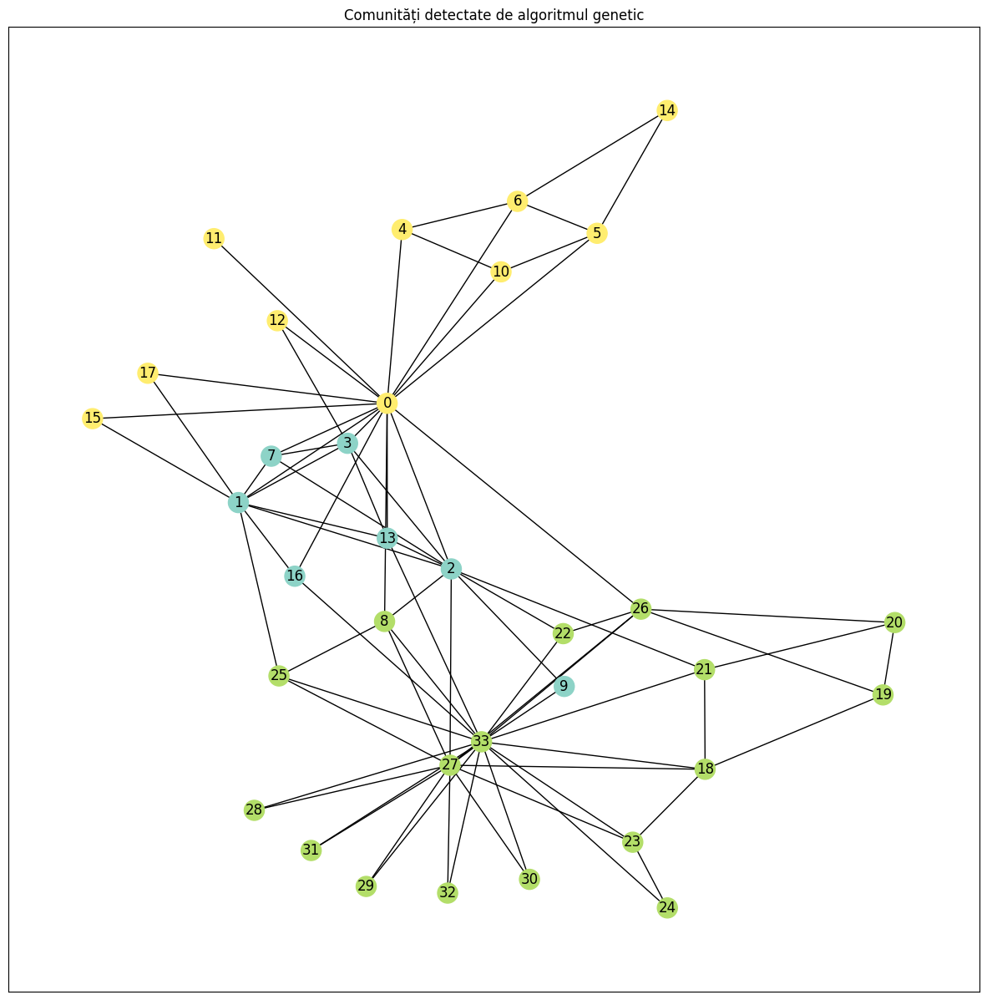

In [16]:
filename = os.path.join(dir_path, 'kar.gml')
run_my_ga(filename, pop_size=50, generations=1000, mutation_rate=0.1, max_comms=3)
